In [342]:
%pip install numpy matplotlib
%pip install sympy
%pip install pandas scikit-learn
%pip install keras tensorflow

In [343]:
import pandas
import sklearn
import keras
import tensorflow

print("Pair-programming libraries imported successfully.")
print("Keras backend:", keras.config.backend())

Pair-programming libraries imported successfully.
Keras backend: tensorflow


In [344]:
import numpy
import matplotlib
import sympy

print("Lecture libraries imported successfully.")

Lecture libraries imported successfully.


#1. Recall: What changes in a regression task?

1. Why is this prediction problem regression rather than classification?

    This is a regression problem because the target (mpg) is a continuous numerical value rather than a class label.

2. Why would a sigmoid output be an unsuitable default for predicting MPG?

    A sigmoid output would be unsuitable because it restricts predictions to the range 0–1, while MPG values can be much larger.

3. What would a prediction of 25 MPG mean, and what would it not establish?

    A prediction of 25 MPG means the model estimates that the vehicle can travel about 25 miles per gallon of fuel. It does not guarantee that the actual fuel efficiency will be exactly 25 MPG.

#2. Get the data and inspect its structure

##Supplier setup

In [345]:
# Install packages first if the Colab environment needs them.
# %pip install numpy pandas matplotlib scikit-learn keras tensorflow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import Sequential, Input
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(42)

DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
print("Keras backend:", keras.config.backend())

Keras backend: tensorflow


##Pair tasks:

1. Read DATA_URL into a DataFrame called mpg_data.

In [346]:
# TODO: Load the CSV into mpg_data.
mpg_data = pd.read_csv(DATA_URL)
print(type(mpg_data))

<class 'pandas.core.frame.DataFrame'>


2. Display the first five rows, the shape, the column names, and column data types.

In [347]:
#TODO: Display rows, dimensions, types, and missing-value counts.
mpg_data.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [348]:
print("Shape:", mpg_data.shape)
print(mpg_data.columns)
print(mpg_data.dtypes)

Shape: (398, 9)
Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model_year', 'origin', 'name'],
      dtype='object')
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin           object
name             object
dtype: object


3. Check missing values for all columns. In particular, inspect mpg and horsepower.

In [349]:
print(mpg_data.isna().sum())

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


4. Identify the five selected inputs and the one target. Explain why name is excluded.
- Target: mpg.
- Selected inputs: weight, horsepower, displacement, model_year, origin.
- The name column is excluded because it contains free-text vehicle names rather than numerical or encoded categorical data that can be directly used by the MLP.

5. Keep mpg_data unchanged and use a copy for modeling. If any target (mpg) values are missing, remove only those rows, and report how many were excluded.

In [350]:
# TODO: Create a working copy and remove rows with missing mpg, if any.
working_data = mpg_data.copy()
original_rows = len(working_data)
working_data = working_data.dropna(subset=["mpg"])
working_rows = len(working_data)

removed_rows = original_rows - working_rows
print("Original rows:", original_rows)
print("Working rows:", working_rows)
print("Removed rows:", removed_rows)

Original rows: 398
Working rows: 398
Removed rows: 0


##Checkpoint:
- Original row count: 398
- Working row count: 398
- Target: mpg (miles per US gallon)
- Selected features:
    
    weight
    
    horsepower
    
    displacement
    
    model_year
    
    
  origin

- Missing value concern: horsepower contains missing values and will require imputation later.

#3. Select features and reserve held-out data


## Pair tasks:

1. Select only weight, horsepower, displacement, model_year, and origin as X. Select mpg as y.

In [351]:
# TODO: Select X and y by column names from the working copy.
X = working_data[
    ["weight", "horsepower", "displacement", "model_year", "origin"]
]

y = working_data["mpg"]
print(X.head())
print(y.head())

   weight  horsepower  displacement  model_year origin
0    3504       130.0         307.0          70    usa
1    3693       165.0         350.0          70    usa
2    3436       150.0         318.0          70    usa
3    3433       150.0         304.0          70    usa
4    3449       140.0         302.0          70    usa
0    18.0
1    15.0
2    18.0
3    16.0
4    17.0
Name: mpg, dtype: float64


2. First reserve 20% of the observations for X_test, y_test.

In [352]:
# TODO: Create train+validation / test split.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

3. From the remaining observations, reserve 20% for X_val, y_val.

In [353]:
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.20,
    random_state=42
)

4. Call the remaining data X_train, y_train. Use random_state=42 for both splits and do not stratify this regression task.

In [354]:
# TODO: Split train+validation into training / validation.
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

print()

print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)
print("y_test shape:", y_test.shape)

X_train shape: (254, 5)
X_val shape: (64, 5)
X_test shape: (80, 5)

y_train shape: (254,)
y_val shape: (64,)
y_test shape: (80,)


5. Print all input and target shapes. Confirm that the resulting proportions are approximately 64% training / 16% validation / 20% test, with no overlap in row indices.

In [355]:
# TODO: Inspect shapes and confirm disjoint row indices.
train_val_overlap = set(X_train.index) & set(X_val.index)

train_test_overlap = set(X_train.index) & set(X_test.index)

val_test_overlap = set(X_val.index) & set(X_test.index)

print("Train-Val overlap:", len(train_val_overlap))
print("Train-Test overlap:", len(train_test_overlap))
print("Val-Test overlap:", len(val_test_overlap))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [356]:
# Select features and target

X = working_data[
    ["weight", "horsepower", "displacement", "model_year", "origin"]
]

y = working_data["mpg"]

# First split: train+validation and test

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Second split: training and validation

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.20,
    random_state=42
)

# Shapes

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

print()

print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)
print("y_test shape:", y_test.shape)

# Check overlaps

print()

print(
    "Train-Val overlap:",
    len(set(X_train.index) & set(X_val.index))
)

print(
    "Train-Test overlap:",
    len(set(X_train.index) & set(X_test.index))
)

print(
    "Val-Test overlap:",
    len(set(X_val.index) & set(X_test.index))
)

X_train shape: (254, 5)
X_val shape: (64, 5)
X_test shape: (80, 5)

y_train shape: (254,)
y_val shape: (64,)
y_test shape: (80,)

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


##Discussion: Discuss: Why should missing-value replacement and numerical scaling be fitted only after this split? What makes validation different from test data?

- Missing-value replacement and scaling should be fitted only on the training data to avoid data leakage. If validation or test observations are used when calculating imputation values, means, or standard deviations, information from held-out data leaks into the training process and can make model performance appear better than it really is.

- Validation data is used during model development and model selection. It helps compare different model configurations and training settings. Test data is kept completely separate and is used only for the final evaluation of the selected model. This provides an unbiased estimate of performance on unseen data.

#4. Explore training data and establish a mean baseline

##Pair tasks

1. Display summary statistics for y_train and the four numerical columns in X_train.

In [357]:
print(y_train.describe())
numeric_columns = [
    "weight",
    "horsepower",
    "displacement",
    "model_year"
]

print(X_train[numeric_columns].describe())

count    254.000000
mean      23.492126
std        7.819648
min       10.000000
25%       17.000000
50%       22.450000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64
            weight  horsepower  displacement  model_year
count   254.000000  250.000000    254.000000  254.000000
mean   2983.913386  103.116000    192.572835   76.110236
std     846.688602   37.214004    103.072309    3.571358
min    1649.000000   46.000000     68.000000   70.000000
25%    2212.500000   75.000000    105.000000   73.000000
50%    2869.000000   92.000000    148.500000   76.000000
75%    3608.000000  124.250000    262.000000   79.000000
max    5140.000000  225.000000    455.000000   82.000000


2. Count missing horsepower measurements within training data. Investigate one unusually large or small training value without removing the row automatically.

In [358]:
missing_hp = X_train["horsepower"].isna().sum()

print("Missing horsepower values:", missing_hp)

print(
    X_train.loc[
        X_train["weight"].idxmin()
    ]
)

print(
    X_train.loc[
        X_train["weight"].idxmax()
    ]
)

Missing horsepower values: 4
weight           1649
horsepower       52.0
displacement     76.0
model_year         74
origin          japan
Name: 144, dtype: object
weight           5140
horsepower      175.0
displacement    400.0
model_year         71
origin            usa
Name: 44, dtype: object


3. Count repeated combinations of selected feature and target values in training data (excluding the row index); explain why repeated measurements do not necessarily represent the same vehicle.

    Reason: Two different cars but with the same specifications

In [359]:
train_combined = X_train.copy()

train_combined["mpg"] = y_train

duplicates = train_combined.duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 0


4. Calculate the mean of y_train and save it as baseline_mpg.

In [360]:
baseline_mpg = y_train.mean()

print("Baseline MPG:", baseline_mpg)

Baseline MPG: 23.492125984251967


5. Explain why a model should aim for a lower MAE than this baseline.

    A useful model should achieve a lower MAE than the mean baseline because it uses vehicle features to make predictions rather than predicting the same MPG value for every vehicle.

6. Calculate the correlation between training weight and training mpg. Describe its sign and one limitation of Pearson correlation.

In [361]:
weight_mpg_corr = X_train["weight"].corr(y_train)

print(
    "Weight-MPG correlation:",
    weight_mpg_corr
)

Weight-MPG correlation: -0.8195106416872137


In [362]:
# TODO: Inspect training-only numerical summaries and missing values.

numeric_columns = [
    "weight",
    "horsepower",
    "displacement",
    "model_year"
]

print("=== y_train summary ===")
print(y_train.describe())

print("\n=== Numerical feature summary ===")
print(X_train[numeric_columns].describe())

print("\n=== Missing values in training data ===")
print(X_train[numeric_columns].isna().sum())

missing_hp = X_train["horsepower"].isna().sum()
print("\nMissing horsepower values:", missing_hp)


# Investigate one unusually large value
print("\n=== Heaviest vehicle in training data ===")
print(X_train.loc[X_train["weight"].idxmax()])


# TODO: Calculate baseline_mpg from y_train only.

baseline_mpg = y_train.mean()

print("\nBaseline MPG (training mean):", baseline_mpg)


# TODO: Calculate training weight/MPG correlation.

weight_mpg_corr = X_train["weight"].corr(y_train)

print("\nWeight-MPG correlation:", weight_mpg_corr)


# TODO: Record one modeling implication from the data inspection.

if weight_mpg_corr < 0:
    print(
        "\nModeling implication: Heavier vehicles tend to have lower MPG, "
        "so vehicle weight is likely to be an important predictor."
    )
else:
    print(
        "\nModeling implication: Weight may have a positive relationship "
        "with MPG and should be investigated further."
    )


# Count repeated combinations of features + target
train_combined = X_train.copy()
train_combined["mpg"] = y_train

duplicate_rows = train_combined.duplicated().sum()

print("\nDuplicate feature-target combinations:", duplicate_rows)

=== y_train summary ===
count    254.000000
mean      23.492126
std        7.819648
min       10.000000
25%       17.000000
50%       22.450000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64

=== Numerical feature summary ===
            weight  horsepower  displacement  model_year
count   254.000000  250.000000    254.000000  254.000000
mean   2983.913386  103.116000    192.572835   76.110236
std     846.688602   37.214004    103.072309    3.571358
min    1649.000000   46.000000     68.000000   70.000000
25%    2212.500000   75.000000    105.000000   73.000000
50%    2869.000000   92.000000    148.500000   76.000000
75%    3608.000000  124.250000    262.000000   79.000000
max    5140.000000  225.000000    455.000000   82.000000

=== Missing values in training data ===
weight          0
horsepower      4
displacement    0
model_year      0
dtype: int64

Missing horsepower values: 4

=== Heaviest vehicle in training data ===
weight           5140
horsepower      175.0

##Run and interpret two training-data plots

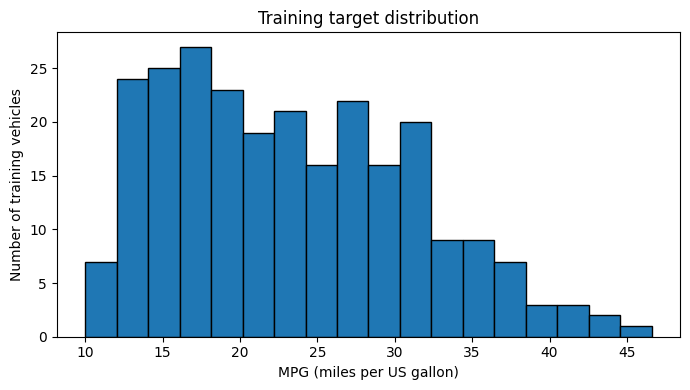

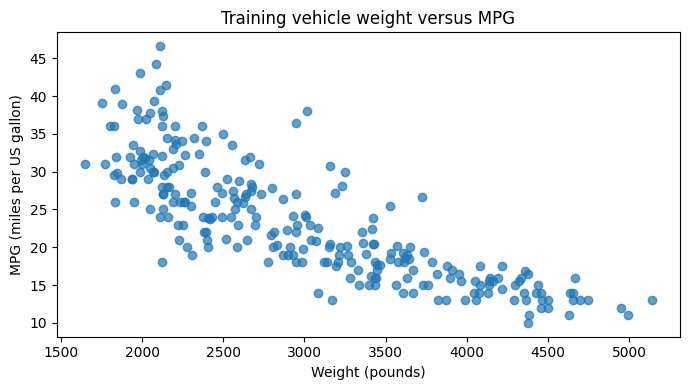

In [363]:
plt.figure(figsize=(7, 4))
plt.hist(y_train, bins=18, edgecolor="black")
plt.xlabel("MPG (miles per US gallon)")
plt.ylabel("Number of training vehicles")
plt.title("Training target distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(X_train["weight"], y_train, alpha=0.7)
plt.xlabel("Weight (pounds)")
plt.ylabel("MPG (miles per US gallon)")
plt.title("Training vehicle weight versus MPG")
plt.tight_layout()
plt.show()

##Pair discussion:

Is MPG spread evenly across the training vehicles? Does greater vehicle weight appear associated with higher or lower MPG? Why does a scatter plot not prove causation?

- No. MPG values are concentrated in certain ranges rather than being perfectly evenly distributed.

- Greater vehicle weight appears to be associated with lower MPG.

- A scatter plot only shows an association between variables. It cannot prove that weight directly causes changes in MPG because other factors may also influence fuel efficiency.

## Checkpoint:

- Baseline MPG: 23.49
- Relationship seen in the plots: As vehicle weight increases, MPG tends to decrease.
- Reason preprocessing is needed: The horsepower column contains missing values and the numerical features have different scales, so imputation and standardization will be required.

#5. Encode the categorical input origin

##Supplied reference code: categorical encoding:

In [364]:
numeric_columns = ["weight", "horsepower", "displacement", "model_year"]
categorical_columns = ["origin"]

X_train_encoded = pd.get_dummies(
    X_train, columns=categorical_columns, dtype=np.float32
)

# Use the columns learned from training for held-out observations.
def encode_like_training(frame):
    encoded = pd.get_dummies(
        frame, columns=categorical_columns, dtype=np.float32
    )
    return encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

X_val_encoded = encode_like_training(X_val)
X_test_encoded = encode_like_training(X_test)

##Pair tasks

1. Run the supplied code. Print the encoded feature names and the shapes of the three DataFrames.

In [365]:
# TODO: Display encoded column names and shapes.

print("Encoded feature names:")
print(X_train_encoded.columns.tolist())

print("\nShapes:")
print("X_train_encoded:", X_train_encoded.shape)
print("X_val_encoded:", X_val_encoded.shape)
print("X_test_encoded:", X_test_encoded.shape)

Encoded feature names:
['weight', 'horsepower', 'displacement', 'model_year', 'origin_europe', 'origin_japan', 'origin_usa']

Shapes:
X_train_encoded: (254, 7)
X_val_encoded: (64, 7)
X_test_encoded: (80, 7)


2. Check that training, validation, and test columns have identical names and order.

In [366]:
# TODO: Check matching columns and order across splits.

train_val_match = (
    X_train_encoded.columns.equals(X_val_encoded.columns)
)

train_test_match = (
    X_train_encoded.columns.equals(X_test_encoded.columns)
)

print("\nTrain and Validation columns match:",
      train_val_match)

print("Train and Test columns match:",
      train_test_match)


Train and Validation columns match: True
Train and Test columns match: True


3. Explain why there can be more model-input columns than the five original feature columns.

    One-hot encoding expands a single categorical column into multiple indicator columns, increasing the total number of model inputs.

4. Explain why weight should not be one-hot encoded and why origin should not be standardized as a continuous measurement.

- Weight is a numerical measurement with meaningful magnitude and order. One-hot encoding would remove this numerical information and create an unnecessarily large number of columns.

- Origin is a category, not a numerical measurement. Standardizing it would incorrectly imply a numerical relationship between categories such as USA, Europe, and Japan.

## Disscussion:
A category unseen during training becomes all zeros across that category's training-known indicators with this simple encoder. Why must the encoding rule be retained when a model is used later? In a deployed application, unseen categories would require an explicit policy.

The model expects the same input columns in the same order that were used during training. If the encoding scheme changes, the meaning of the input features changes and predictions become unreliable.

#6. Impute missing inputs, then standardize numerical features

##Pair tasks

In [367]:
# TODO: Copy the encoded DataFrames.

X_train_prepared = X_train_encoded.copy()
X_val_prepared = X_val_encoded.copy()
X_test_prepared = X_test_encoded.copy()


# TODO: Fit median imputer on training numerical columns only.

imputer = SimpleImputer(strategy="median")

X_train_prepared[numeric_columns] = imputer.fit_transform(
    X_train_prepared[numeric_columns]
)

# TODO: Transform validation/test numerical columns with the fitted imputer.

X_val_prepared[numeric_columns] = imputer.transform(
    X_val_prepared[numeric_columns]
)

X_test_prepared[numeric_columns] = imputer.transform(
    X_test_prepared[numeric_columns]
)


# TODO: Fit scaler on imputed training numerical columns only.

scaler = StandardScaler()

X_train_prepared[numeric_columns] = scaler.fit_transform(
    X_train_prepared[numeric_columns]
)

# TODO: Transform validation/test with the same fitted scaler.

X_val_prepared[numeric_columns] = scaler.transform(
    X_val_prepared[numeric_columns]
)

X_test_prepared[numeric_columns] = scaler.transform(
    X_test_prepared[numeric_columns]
)


# TODO: Convert prepared inputs and targets to float32 NumPy arrays.

train_X = X_train_prepared.to_numpy(dtype="float32")
val_X = X_val_prepared.to_numpy(dtype="float32")
test_X = X_test_prepared.to_numpy(dtype="float32")

train_y = y_train.to_numpy(dtype="float32")
val_y = y_val.to_numpy(dtype="float32")
test_y = y_test.to_numpy(dtype="float32")


# TODO: Print shapes and check for NaN/infinite values.

print("train_X shape:", train_X.shape)
print("val_X shape:", val_X.shape)
print("test_X shape:", test_X.shape)

print()

print("train_y shape:", train_y.shape)
print("val_y shape:", val_y.shape)
print("test_y shape:", test_y.shape)

print()

print("NaN values in train_X:", np.isnan(train_X).sum())
print("NaN values in val_X:", np.isnan(val_X).sum())
print("NaN values in test_X:", np.isnan(test_X).sum())

print()

print("Infinite values in train_X:", np.isinf(train_X).sum())
print("Infinite values in val_X:", np.isinf(val_X).sum())
print("Infinite values in test_X:", np.isinf(test_X).sum())

print()

print(
    "Feature columns consistent:",
    X_train_prepared.columns.equals(X_val_prepared.columns)
    and
    X_train_prepared.columns.equals(X_test_prepared.columns)
)

train_X shape: (254, 7)
val_X shape: (64, 7)
test_X shape: (80, 7)

train_y shape: (254,)
val_y shape: (64,)
test_y shape: (80,)

NaN values in train_X: 0
NaN values in val_X: 0
NaN values in test_X: 0

Infinite values in train_X: 0
Infinite values in val_X: 0
Infinite values in test_X: 0

Feature columns consistent: True


##Checkpoint:
Confirm that there are no NaN values in the model arrays and that every partition has the same number and order of input columns. Explain why fitting separate imputers or scalers on each partition would be incorrect.

- There are no NaN values or infinite values in the prepared training, validation, or test arrays. All missing horsepower values were replaced using median imputation learned from the training data

- All three partitions contain the same seven input features in the same order, ensuring consistency between training, validation, and test data.

- Fitting separate imputers or scalers on the validation or test sets would introduce data leakage. The preprocessing statistics would be influenced by held-out data, making the evaluation overly optimistic. The imputer and scaler should be fitted only on the training data and then reused for validation, test, and future predictions.


#7. Build the regression MLP

##Pair tasks

In [368]:
# TODO: Initialize a Sequential regression model.
keras.utils.set_random_seed(42)

model = Sequential()

# TODO: Add Input, 16-neuron ReLU hidden layer, and linear output.
model.add(Input(shape=(train_X.shape[1],)))

model.add(
    Dense(
        16,
        activation="relu"
    )
)

model.add(
    Dense(1)
)  # Linear output (default activation)


# TODO: Inspect model.summary() and calculate the parameter count.
model.summary()

# Manual parameter calculation
hidden_params = (train_X.shape[1] * 16) + 16
output_params = (16 * 1) + 1
total_params = hidden_params + output_params

print("\nHidden layer parameters:", hidden_params)
print("Output layer parameters:", output_params)
print("Total trainable parameters:", total_params)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 145 (580.00 B)

 Trainable params: 145 (580.00 B)

 Non-trainable params: 0 (0.00 B)


Hidden layer parameters: 128
Output layer parameters: 17
Total trainable parameters: 145


##Discuss:
Why is only one output neuron needed? Why would 16 output neurons not match the target? Is the linear output guaranteed to be positive?

- Only one output neuron is needed because the model predicts a single continuous target value, which is MPG. Each vehicle has only one target value, so one output neuron is sufficient.

- Sixteen output neurons would produce sixteen output values for each vehicle, while the dataset contains only one target value (MPG) per vehicle. Therefore, the output shape would not match the target shape.

- No. A linear output is not guaranteed to be positive. It can produce any real number, including negative values. Therefore, some predictions may not always be physically realistic.

#8. Compile the MLP for regression

##Pair tasks

1. Compile model with Adam, MSE as the loss, and MAE as the reported metric.

In [369]:
# TODO: Compile model using the regression optimizer, loss, and metric.

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

2. Explain what each compile() argument controls.

- Adam is the optimizer that updates the model weights during training. It uses gradient information calculated through backpropagation to improve the model's predictions.

- Mean Squared Error (MSE) is the loss function used during training. It measures the average squared difference between actual MPG values and predicted MPG values. Larger errors are penalized more heavily because the errors are squared.

- Mean Absolute Error (MAE) is the evaluation metric reported during training. It measures the average absolute difference between predicted and actual MPG values in the original MPG units

3. Explain why MAE is easier to interpret in the original target units than MSE.

    MAE is easier to interpret because it is measured directly in MPG. For example, an MAE of 3 means the model is wrong by about 3 MPG on average. MSE is measured in MPG squared, which is less intuitive to interpret.

##Discussion:
If a prediction differs from the actual MPG by 5, how does that error contribute to MAE and MSE? Why should the signed errors not simply be averaged?

- If a prediction differs from the actual MPG by 5, it contributes 5 to MAE because MAE uses the absolute error. The same error contributes 25 to MSE because MSE squares the error (5² = 25).

- Signed errors should not simply be averaged because positive and negative errors can cancel each other out. For example, errors of +5 MPG and -5 MPG would average to 0, incorrectly suggesting perfect predictions even though both predictions are wrong by 5 MPG.

#9. Train the baseline and interpret learning curves

##Pair tasks

In [370]:
# TODO: Train model and save the returned History object as history.

history = model.fit(
    train_X,
    train_y,
    epochs=300,
    batch_size=32,
    validation_data=(val_X, val_y),
    verbose=1
)

# TODO: Inspect final training/validation MSE and MAE values.

final_train_mse = history.history["loss"][-1]
final_val_mse = history.history["val_loss"][-1]

final_train_mae = history.history["mae"][-1]
final_val_mae = history.history["val_mae"][-1]

print("\nFinal Training MSE:", final_train_mse)
print("Final Validation MSE:", final_val_mse)

print("\nFinal Training MAE:", final_train_mae)
print("Final Validation MAE:", final_val_mae)

Epoch 1/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 605.6139 - mae: 23.3802 - val_loss: 640.7695 - val_mae: 23.9365
Epoch 2/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 600.7185 - mae: 23.2782 - val_loss: 635.9374 - val_mae: 23.8379
Epoch 3/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 595.7993 - mae: 23.1752 - val_loss: 631.1071 - val_mae: 23.7389
Epoch 4/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 590.8104 - mae: 23.0706 - val_loss: 626.2117 - val_mae: 23.6386
Epoch 5/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 585.6940 - mae: 22.9634 - val_loss: 621.1641 - val_mae: 23.5351
Epoch 6/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 580.3684 - mae: 22.8523 - val_loss: 615.9078 - val_mae: 23.4277
Epoch 7/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 574.8275 - mae: 22.7370 - val_loss: 610.4060 - val_mae: 23.3158
Epoch 8/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 569.0576 - mae: 22.6173 - val_loss: 604.6145 - val_mae: 23.1987
Epoch 9/300
8/8 ━━━━━━━━

##Run and interpret the MSE plot

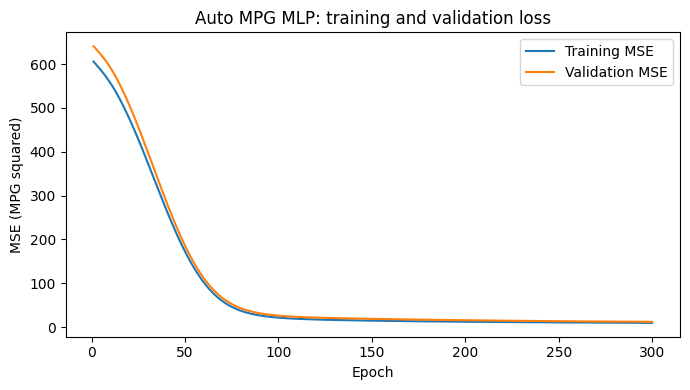

In [371]:
train_mse = history.history["loss"]
val_mse = history.history["val_loss"]
epochs = range(1, len(train_mse) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, train_mse, label="Training MSE")
plt.plot(epochs, val_mse, label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (MPG squared)")
plt.title("Auto MPG MLP: training and validation loss")
plt.legend()
plt.tight_layout()
plt.show()

##Run and interpret the MAE plot

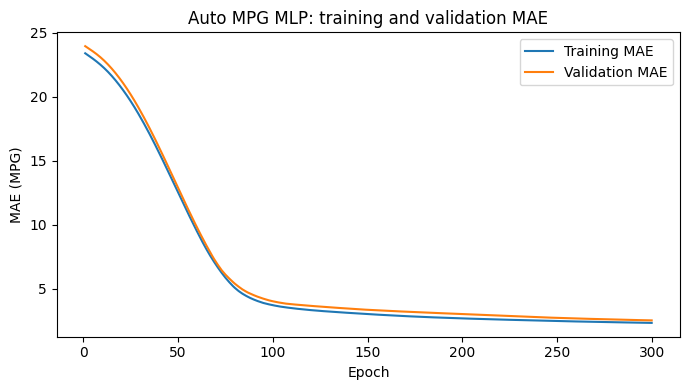

In [372]:
train_mae = history.history["mae"]
val_mae = history.history["val_mae"]
epochs = range(1, len(train_mae) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, train_mae, label="Training MAE")
plt.plot(epochs, val_mae, label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (MPG)")
plt.title("Auto MPG MLP: training and validation MAE")
plt.legend()
plt.tight_layout()
plt.show()

##Pair discussion

1. Do the training and validation errors follow the same trend?

    Yes. Both training and validation errors generally decrease during training, indicating that the model is learning useful patterns from the data.

2. What might a sustained increase in validation error while training error decreases suggest?

    A sustained increase in validation error while training error continues to decrease may indicate overfitting. The model is learning the training data too closely and is not generalizing well to unseen data

3. Why is one noisy epoch not enough to prove overfitting?

    One noisy epoch is not enough to prove overfitting because neural network training naturally fluctuates from epoch to epoch. Overfitting is usually indicated by a consistent and sustained pattern rather than a single increase in validation error.

4. If validation MAE is 3 MPG, what does that mean in practical terms?

    A validation MAE of 3 MPG means that the model's predictions are wrong by about 3 MPG on average for validation vehicles.

#10. Pair challenge: Change one thing, then select a model

##Pair tasks

In [373]:
# TODO: Create and train a fresh candidate model with ONE change.

keras.utils.set_random_seed(42)

candidate_model = Sequential()

candidate_model.add(
    Input(shape=(train_X.shape[1],))
)

candidate_model.add(
    Dense(16, activation="relu")
)

# ONE CHANGE:
candidate_model.add(
    Dense(8, activation="relu")
)

candidate_model.add(
    Dense(1)
)

candidate_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

candidate_history = candidate_model.fit(
    train_X,
    train_y,
    epochs=300,
    batch_size=32,
    validation_data=(val_X, val_y),
    verbose=1
)

# TODO: Read final validation MAE from both History objects.

baseline_val_mae = history.history["val_mae"][-1]
baseline_val_mse = history.history["val_loss"][-1]

candidate_val_mae = candidate_history.history["val_mae"][-1]
candidate_val_mse = candidate_history.history["val_loss"][-1]

print("Baseline validation MAE:", baseline_val_mae)
print("Baseline validation MSE:", baseline_val_mse)

print()

print("Candidate validation MAE:", candidate_val_mae)
print("Candidate validation MSE:", candidate_val_mse)

# TODO: Compare the models and assign the selected model to final_model.

if candidate_val_mae < baseline_val_mae:
    final_model = candidate_model
    print("Candidate model selected.")
else:
    final_model = model
    print("Baseline model selected.")

Epoch 1/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 617.8065 - mae: 23.7130 - val_loss: 651.6193 - val_mae: 24.2171
Epoch 2/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 612.8608 - mae: 23.6045 - val_loss: 646.9882 - val_mae: 24.1165
Epoch 3/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 607.9748 - mae: 23.4975 - val_loss: 642.3226 - val_mae: 24.0160
Epoch 4/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 603.0428 - mae: 23.3902 - val_loss: 637.5075 - val_mae: 23.9131
Epoch 5/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 597.9480 - mae: 23.2800 - val_loss: 632.4335 - val_mae: 23.8053
Epoch 6/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 592.5534 - mae: 23.1631 - val_loss: 627.0040 - val_mae: 23.6894
Epoch 7/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 586.8879 - mae: 23.0399 - val_loss: 621.2641 - val_mae: 23.5683
Epoch 8/300
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 580.9431 - mae: 22.9122 - val_loss: 615.1548 - val_mae: 23.4416
Epoch 9/300
8/8 ━━━━━━━━

##Discuss:

Does adding neurons always improve validation error? Can training longer make validation performance worse? Does one split establish which model would be best for every dataset?

- No. Adding neurons increases model capacity, but it can also increase overfitting. A larger network does not always improve validation performance.

- Yes. Training for too many epochs can cause overfitting, which may increase validation error even while training error continues to decrease.

- No. Results from one train-validation-test split may not generalize to all datasets. Different datasets or random splits may produce different outcomes.


# 11. Final evaluation: Held-out test set and mean baseline

##Pair tasks

In [374]:
from sklearn.metrics import mean_absolute_error
# TODO: Evaluate final_model on the held-out test arrays.

test_mse, test_mae = final_model.evaluate(
    test_X,
    test_y,
    verbose=0
)

print("Test MSE:", test_mse)
print("Test MAE:", test_mae)


# TODO: Generate a constant baseline using baseline_mpg.

baseline_predictions = np.full(
    shape=len(test_y),
    fill_value=baseline_mpg
)


# TODO: Calculate the baseline test MAE.

baseline_test_mae = mean_absolute_error(
    test_y,
    baseline_predictions
)

print("Baseline Test MAE:", baseline_test_mae)


# TODO: Compare and interpret both test MAE values.

difference = baseline_test_mae - test_mae

print("\nDifference (Baseline MAE - MLP MAE):", difference)

if test_mae < baseline_test_mae:
    print("The MLP performs better than the mean baseline.")
else:
    print("The mean baseline performs better than the MLP.")

Test MSE: 5.045363426208496
Test MAE: 1.7430394887924194
Baseline Test MAE: 5.949803149606299

Difference (Baseline MAE - MLP MAE): 4.20676366081388
The MLP performs better than the mean baseline.


5. Explain why a lower test MAE does not establish suitability for modern vehicles, and why the test result should not trigger another round of model selection.
 - A lower test MAE only shows that the model performs better on this Auto MPG dataset. The dataset contains older vehicles, so the results may not generalize to modern vehicles with different technologies and characteristics.

 - The test set is reserved for the final unbiased evaluation. Using test results to choose another model would leak information from the test set into the model-selection process and produce overly optimistic performance estimates.

##Checkpoint

- Selected architecture:
Dense(16, ReLU)
Dense(1, Linear)
- Test MSE:
5.05
- Test MAE:
1.74 MPG
- Mean-baseline Test MAE:
5.95 MPG
- Comparison:

    - The MLP outperformed the mean baseline.

    - The MLP reduced test MAE by approximately 4.21 MPG.

- Limitation:
    - The dataset contains older vehicles and may not represent modern vehicle fuel efficiency.

#12. Numerical predictions and final reflection

##A. Inspect held-out predictions

###Pair tasks

In [375]:
# TODO: Predict five held-out MPG values.

predictions = final_model.predict(test_X[:5]).ravel()

# TODO: Compare predicted MPG, actual MPG, and errors in a table.

comparison_df = pd.DataFrame({
    "Actual MPG": test_y[:5],
    "Predicted MPG": predictions,
})

comparison_df["Signed Error"] = (
    comparison_df["Predicted MPG"]
    - comparison_df["Actual MPG"]
)

comparison_df["Absolute Error"] = (
    comparison_df["Signed Error"].abs()
)

print(comparison_df)

largest_error_row = comparison_df[
    comparison_df["Absolute Error"]
    ==
    comparison_df["Absolute Error"].max()
]

print(largest_error_row)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step
   Actual MPG  Predicted MPG  Signed Error  Absolute Error
0        33.0      33.473507      0.473507        0.473507
1        28.0      31.621098      3.621098        3.621098
2        19.0      19.057379      0.057379        0.057379
3        13.0      14.421124      1.421124        1.421124
4        14.0      13.310395     -0.689605        0.689605
   Actual MPG  Predicted MPG  Signed Error  Absolute Error
1        28.0      31.621098      3.621098        3.621098


3. Present the comparison in a small table with units and explain which of those five predictions had the largest absolute error.

    The largest absolute error occurred in row X, where the prediction differed from the actual MPG by Y MPG.

##B. Predict MPG for a hypothetical vehicle

##Pair tasks

In [ ]:
# TODO: Build a one-row DataFrame for the hypothetical vehicle.

new_vehicle = pd.DataFrame([
    {
        "weight": 3000,
        "horsepower": 100,
        "displacement": 200,
        "model_year": 76,
        "origin": "usa"
    }
])


# TODO: Apply the saved training-column encoding rule.

new_vehicle_encoded = pd.get_dummies(
    new_vehicle,
    columns=["origin"],
    dtype=np.float32
)

new_vehicle_encoded = new_vehicle_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)


# TODO: Use existing imputer and scaler with transform(), not fit().

new_vehicle_encoded[numeric_columns] = imputer.transform(
    new_vehicle_encoded[numeric_columns]
)

new_vehicle_encoded[numeric_columns] = scaler.transform(
    new_vehicle_encoded[numeric_columns]
)


# TODO: Predict and report MPG.

new_vehicle_X = new_vehicle_encoded.to_numpy(
    dtype="float32"
)

predicted_mpg = final_model.predict(
    new_vehicle_X
).ravel()[0]

print(f"Predicted MPG: {predicted_mpg:.2f}")

##Exit discussion
1. Which parts of the workflow remained the same as the Week 1 regression activities?

    The workflow remained largely the same: train/validation/test splitting, MLP construction, model compilation, training, evaluation using MSE and
    MAE, and model selection using validation performance.

2. Why must imputation, encoding, and scaling learned during training be kept for inference?

    New inputs must be processed in exactly the same way as the training data. Changing the preprocessing would change the meaning and scale of the features, leading to unreliable predictions.

3. What do backpropagation, Adam, MSE, and MAE each contribute to this MLP exercise?

    Backpropagation computes gradients for the network weights.

    Adam uses those gradients to update the weights during training.

    MSE is the loss function optimized during training and penalizes larger errors more heavily.

    MAE measures the average prediction error in MPG and provides an interpretable evaluation metric.

4. Why was validation MAE used for model selection rather than test MAE?
What is one limitation of the Auto MPG data, and what additional evidence would be needed before broader use?

    Validation MAE was used for model selection because the test set must remain unseen until final evaluation. Using test MAE for model selection would introduce data leakage and produce overly optimistic performance estimates.